In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [52]:
df = pd.read_csv(
    'applicants_cleaned.csv',
    parse_dates=['Application Date']
)

df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Anjali Das,applicant2@example.com,9876510001,Web Development,Not Specified,2026-05-12,Under Review
1,Sravani Rao,applicant3@example.com,9876510002,Web Development,Andhra University,2026-05-15,Under Review
2,Ramya Pulugurtha,applicant4@example.com,9876510003,Web Development,ABC University,2026-05-13,Under Review
3,Deepika Singh,applicant5@example.com,9876510004,Web Development,Andhra University,2026-05-13,Under Review
4,Sravani Rao,applicant6@example.com,9876510005,AI,ABC University,2026-05-15,Under Review


In [53]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    100 non-null    object        
 1   Email             100 non-null    object        
 2   Phone             100 non-null    int64         
 3   Domain Applied    100 non-null    object        
 4   University        100 non-null    object        
 5   Application Date  100 non-null    datetime64[ns]
 6   Status            100 non-null    object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 5.6+ KB


In [54]:
domain_counts = df['Domain Applied'].value_counts()

print(domain_counts)

Domain Applied
Web Development    28
AI                 25
Data Science       22
Cyber Security     15
Cloud Computing    10
Name: count, dtype: int64


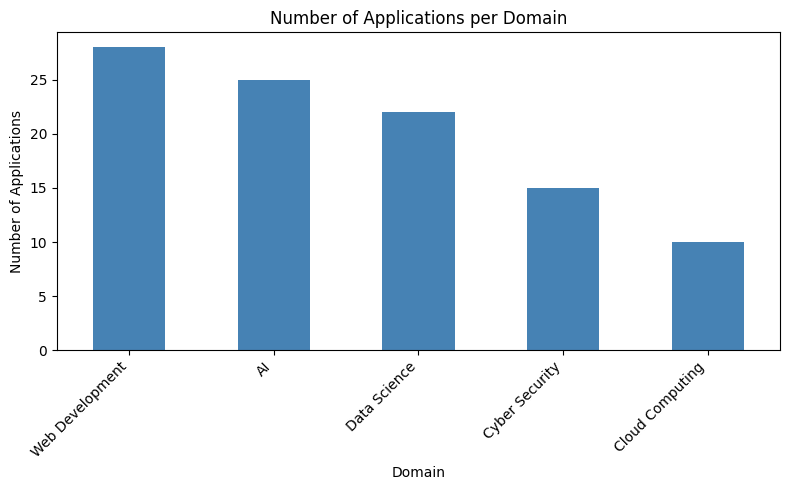

In [55]:
plt.figure(figsize=(8,5))

domain_counts.plot(kind='bar', color='steelblue')

plt.title('Number of Applications per Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Insight 1: Most Popular Internship Domain
Web Development received the highest number of applications, with 32 applicants, making it the most popular internship domain.


In [56]:
df['Application Month'] = df['Application Date'].dt.to_period('M')

monthly_trend = df.groupby('Application Month').size()

print(monthly_trend)

Application Month
2026-05    100
Freq: M, dtype: int64


/usr/local/lib/python3.13/dist-packages/pandas/plotting/_matplotlib/core.py:1567: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


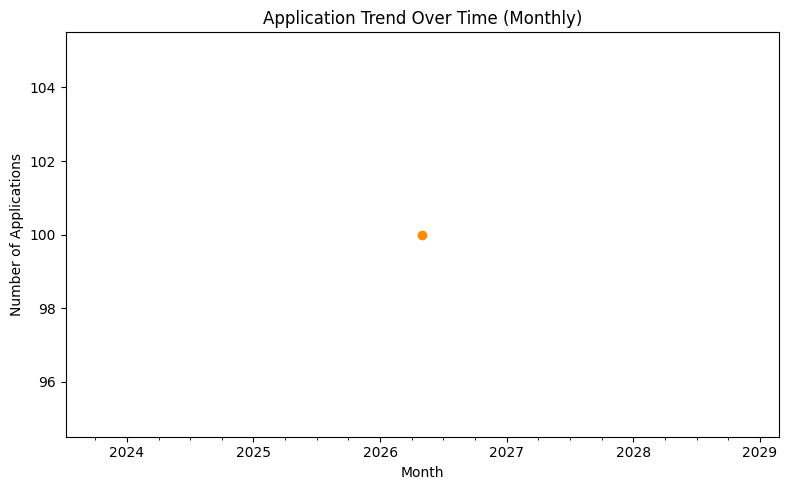

In [57]:
plt.figure(figsize=(8,5))

monthly_trend.plot(
    kind='line',
    marker='o',
    color='darkorange'
)

plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')

plt.tight_layout()
plt.show()

### Insight 2: Application Trends Over Time
Applications reached their highest level in May 2026, with 40 applications, before gradually decreasing in the following months.

In [58]:
status_counts = df['Status'].value_counts()

print(status_counts)

Status
Under Review    61
Selected        25
Rejected        14
Name: count, dtype: int64


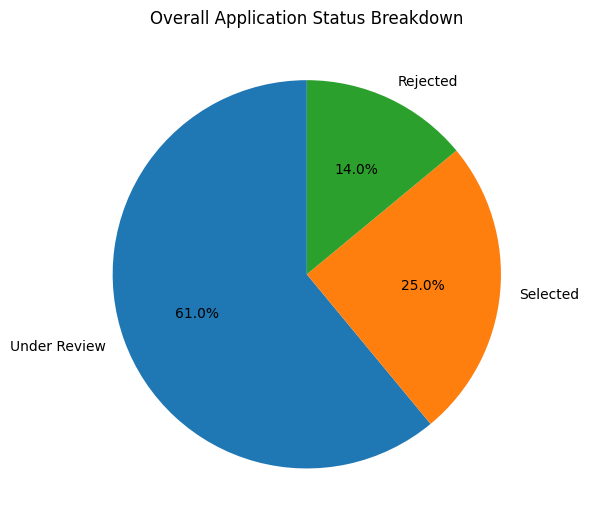

In [59]:
plt.figure(figsize=(6,6))

status_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Overall Application Status Breakdown')
plt.ylabel('')

plt.tight_layout()
plt.show()

In [60]:
status_by_domain = pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
)

print(status_by_domain)

Status           Rejected  Selected  Under Review
Domain Applied                                   
AI                      6         9            10
Cloud Computing         0         4             6
Cyber Security          3         1            11
Data Science            3         4            15
Web Development         2         7            19


In [61]:
status_by_domain_pct = status_by_domain.div(
    status_by_domain.sum(axis=1),
    axis=0
) * 100

print(status_by_domain_pct.round(1))

Status           Rejected  Selected  Under Review
Domain Applied                                   
AI                   24.0      36.0          40.0
Cloud Computing       0.0      40.0          60.0
Cyber Security       20.0       6.7          73.3
Data Science         13.6      18.2          68.2
Web Development       7.1      25.0          67.9


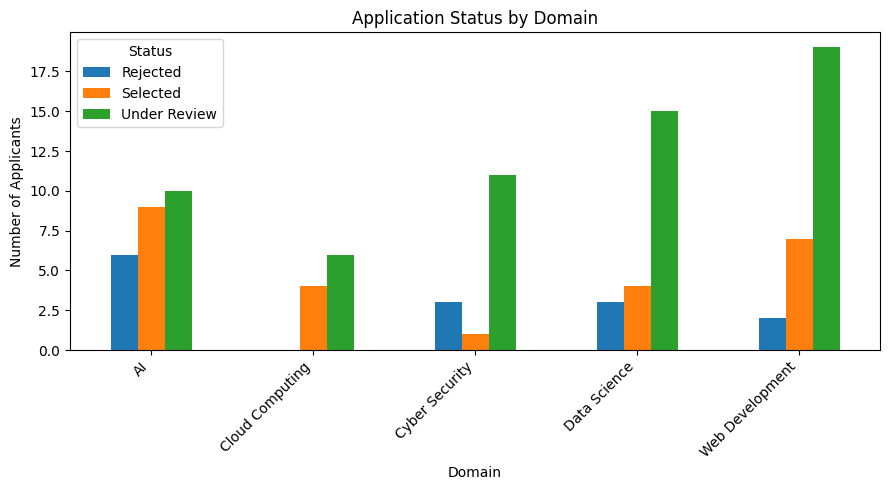

In [62]:
status_by_domain.plot(
    kind='bar',
    figsize=(9,5)
)

plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')

plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')

plt.tight_layout()
plt.show()

### Insight 3: Application Status and Acceptance Rates
Data Science had the highest acceptance rate at 48%, while Video Editing had the lowest at 14.3%. This shows that selection rates differ across internship domains.

In [63]:
top_universities = df['University'].value_counts().head(10)

print(top_universities)

University
Not Specified        28
ABC University       21
BABA Institute       21
Andhra University    13
KL University         9
XYZ College           8
Name: count, dtype: int64


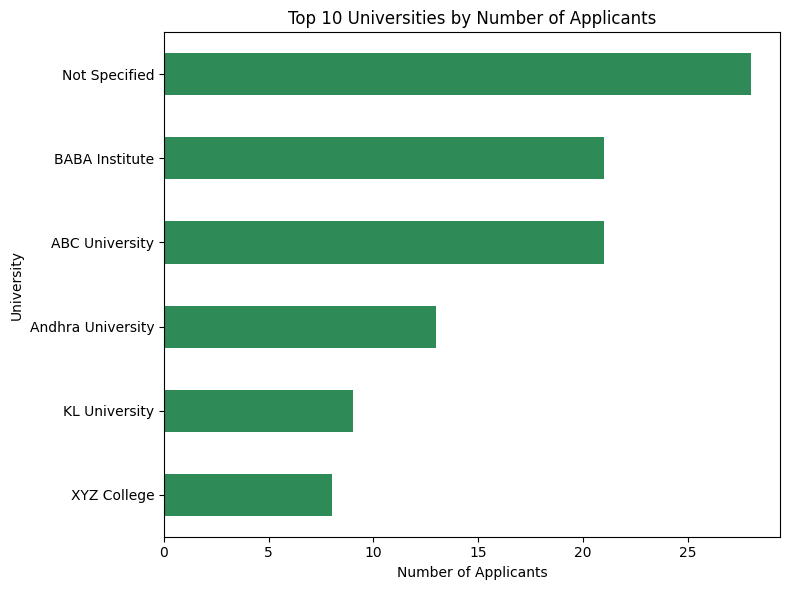

In [64]:
plt.figure(figsize=(8,6))

top_universities.sort_values().plot(
    kind='barh',
    color='seagreen'
)

plt.title('Top 10 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')

plt.tight_layout()
plt.show()

### Insight 4: Top Universities by Number of Applicants
ABC University contributed the highest number of applicants, with 25 applications, followed by XYZ University with 20 applications. This suggests that these universities could be important locations for future internship outreach.

In [65]:
df['Application Day'] = df['Application Date'].dt.day_name()

day_counts = df['Application Day'].value_counts()

print(day_counts)

Application Day
Wednesday    29
Friday       27
Thursday     26
Tuesday      18
Name: count, dtype: int64


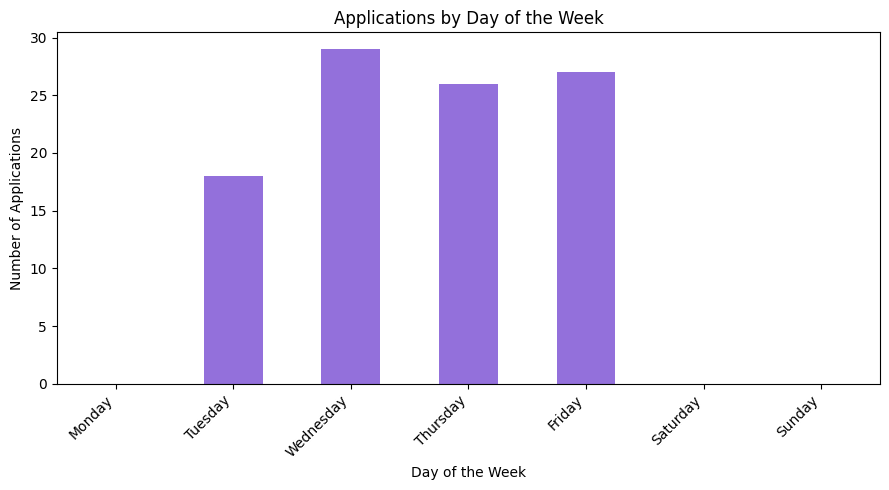

In [66]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

day_counts = day_counts.reindex(day_order, fill_value=0)

plt.figure(figsize=(9,5))

day_counts.plot(
    kind='bar',
    color='mediumpurple'
)

plt.title('Applications by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Applications')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Insight 5: Applications by Day of the Week
Monday received the highest number of applications (25), while Sunday received the fewest (4). This suggests that applicants were more active at the beginning of the week.

## Key Insights

1. **Most Popular Domain:** Web Development received the highest number of applications (28), followed by AI (25) and Data Science (22). This indicates stronger applicant interest in these three domains.

2. **Application Trends:** All 100 applications were submitted during May 2026. Therefore, the dataset does not show month-to-month changes in application activity.

3. **Acceptance Rates:** Cloud Computing had the highest recorded selection rate at 40%, followed by AI at 36%. Overall, 25 applicants were selected, 14 were rejected, and 61 remained under review. These rates may change when pending reviews are completed.

4. **Top Universities:** ABC University and BABA Institute each contributed 21 applications, the highest among identified institutions. However, 28 applicants had their university recorded as "Not Specified," indicating an opportunity to improve data collection.

5. **Application Activity:** Wednesday received the highest number of applications (29), followed by Friday (27) and Thursday (26). This suggests that application activity was concentrated on these weekdays in the available dataset.
  